# Training-free token pruning for ViT-Base, part 2: benchmark harness and full sweep (T4)

**Runtime: T4 GPU, fp32.**
1. FLOPs (`FlopCounterMode`), latency (CUDA events), `torch.profiler` breakdown at batch 1 and 32
2. Full sweep on all 3,925 Imagenette validation images: prune after block 3 / 6 / 9 × drop 10–70%,
   with **interleaved A/B timing** (baseline and pruned alternate in rounds; speedup = median of
   per-round ratios) so GPU clock drift hits both arms equally

Outputs are from the recorded run.

In [ ]:
# Shared setup for this notebook (added during cleanup so it runs top to bottom in a fresh runtime)
!pip install timm --quiet
!pip uninstall -y torchao -q          # Colab's torchao 0.10 breaks peft's import check

import os, copy, tarfile, urllib.request, statistics, time
import numpy as np, pandas as pd, torch, timm
from torch import nn
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
model = timm.create_model("vit_base_patch16_224", pretrained=True).eval().to(device)
transform = timm.data.create_transform(**timm.data.resolve_data_config({}, model=model))
LAYERS, KS = [3, 6, 9], [0.1, 0.3, 0.5, 0.7]   # prune blocks and drop fractions swept
WARMUP, ROUNDS, ITERS = 10, 7, 15             # interleaved A/B timing

In [ ]:
import torch
from torch import nn
class PrunedViT(nn.Module):
    """Runs blocks 0..prune_layer (inclusive), scores patches by CLS->patch attention captured
    inside block `prune_layer`, drops the lowest-scoring `drop_frac` of patches, then runs the
    remaining blocks on the shorter sequence. Call .close() to restore the model."""
    def __init__(self, model, prune_layer=6, drop_frac=0.3):
        super().__init__()
        self.model, self.prune_layer, self.drop_frac = model, prune_layer, drop_frac
        attn = model.blocks[prune_layer].attn
        self._attn_mod, self._orig_fused = attn, attn.fused_attn
        attn.fused_attn = False                        # eager path so the attention matrix exists
        self._attn = None
        self._h = attn.attn_drop.register_forward_hook(self._grab)
    def _grab(self, mod, inp, out):
        self._attn = inp[0]                            # (B, heads, N, N) post-softmax
    def close(self):
        self._h.remove(); self._attn_mod.fused_attn = self._orig_fused
    def forward(self, x):
        m = self.model
        x = m.patch_embed(x); x = m._pos_embed(x); x = m.patch_drop(x); x = m.norm_pre(x)
        for blk in m.blocks[: self.prune_layer + 1]:
            x = blk(x)
        B, N, D = x.shape
        n_patches = N - 1
        n_drop = int(n_patches * self.drop_frac)
        if n_drop > 0:
            scores = self._attn.mean(dim=1)[:, 0, 1:]
            kept = scores.topk(n_patches - n_drop, dim=1, largest=True).indices.sort(dim=1).values
            patches = x[:, 1:].gather(1, kept.unsqueeze(-1).expand(-1, -1, D))
            x = torch.cat([x[:, :1], patches], dim=1)
        for blk in m.blocks[self.prune_layer + 1 :]:
            x = blk(x)
        x = m.norm(x)
        return m.forward_head(x)

In [ ]:
import torch
IMAGENETTE_WNIDS = {  # wnid -> ImageNet-1k class index
 "n01440764":0,"n02102040":217,"n02979186":482,"n03000684":491,"n03028079":497,
 "n03394916":566,"n03417042":569,"n03425413":571,"n03445777":574,"n03888257":701}

@torch.no_grad()
def run_logits(fn, loader, device):
    outs = []
    for xb, _ in loader:
        outs.append(fn(xb.to(device)).cpu())
    return torch.cat(outs)

def metrics(logits, base_logits, y_in1k):
    pred, bpred = logits.argmax(1), base_logits.argmax(1)
    p = logits.softmax(-1); bp = base_logits.softmax(-1)
    idx = torch.arange(len(y_in1k))
    return dict(
        agree_top1 = (pred == bpred).float().mean().item(),
        acc        = (pred == y_in1k).float().mean().item(),
        ptrue      = p[idx, y_in1k].mean().item(),
        ptrue_drop = (bp[idx, y_in1k] - p[idx, y_in1k]).mean().item(),
        max_abs_diff_vs_base = (logits - base_logits).abs().max().item(),
    )

In [ ]:
import torch, time, statistics
from torch.utils.flop_counter import FlopCounterMode

def count_gflops(fn, x):
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        fn(x)
    return fc.get_total_flops() / 1e9

@torch.no_grad()
def bench_ms(fn, x, warmup=20, iters=100):
    """Median latency (ms) of fn(x). CUDA events on GPU, perf_counter on CPU."""
    for _ in range(warmup): fn(x)
    times = []
    if x.is_cuda:
        torch.cuda.synchronize()
        for _ in range(iters):
            s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            s.record(); fn(x); e.record(); torch.cuda.synchronize()
            times.append(s.elapsed_time(e))
    else:
        for _ in range(iters):
            t = time.perf_counter(); fn(x); times.append((time.perf_counter() - t) * 1e3)
    return statistics.median(times), min(times)


@torch.no_grad()
def bench_pair(fn_a, fn_b, x, warmup=10, rounds=7, iters=15):
    """Interleaved A/B timing so clock/thermal drift hits both equally.
    Returns (median ms of A, median ms of B, median of per-round A/B ratio)."""
    def one_round(fn):
        ts = []
        for _ in range(iters):
            if x.is_cuda:
                s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
                s.record(); fn(x); e.record(); torch.cuda.synchronize(); ts.append(s.elapsed_time(e))
            else:
                t = time.perf_counter(); fn(x); ts.append((time.perf_counter() - t) * 1e3)
        return statistics.median(ts)
    for _ in range(warmup): fn_a(x); fn_b(x)
    if x.is_cuda: torch.cuda.synchronize()
    a, b = [], []
    for r in range(rounds):
        if r % 2 == 0: a.append(one_round(fn_a)); b.append(one_round(fn_b))
        else:          b.append(one_round(fn_b)); a.append(one_round(fn_a))
    ratios = [ai / bi for ai, bi in zip(a, b)]
    return statistics.median(a), statistics.median(b), statistics.median(ratios)

## 1. Single-shot benchmark (batch 1 and 32)
First pass. Its baseline median disagreed with its own minimum and with the profiler by ~10% (T4 clock
drift), which is why the sweep in section 3 uses interleaved timing. Treat these speedups as approximate.

In [ ]:
BATCH_SIZES = [1, 32]
KS = [0.1, 0.3, 0.5, 0.7]
xs = {bs: torch.randn(bs, 3, 224, 224, device=device) for bs in BATCH_SIZES}
rows = []
for bs, x in xs.items():
    ms, mn = bench_ms(model, x)
    rows.append(dict(config="fused baseline", K=None, batch=bs, GFLOPs_per_img=count_gflops(model, x)/bs, median_ms=ms, min_ms=mn))
pruner = PrunedViT(model, prune_layer=6, drop_frac=0.0)   # flips block 6 to eager attention

In [1]:
for bs, x in xs.items():
    for K in [0.0] + KS:
        pruner.drop_frac = K
        ms, mn = bench_ms(pruner, x)
        rows.append(dict(config="wrapper", K=K, batch=bs, GFLOPs_per_img=count_gflops(pruner, x)/bs, median_ms=ms, min_ms=mn))
df = pd.DataFrame(rows)
base = df[df.config == "fused baseline"].set_index("batch")
df["speedup_vs_fused"] = df.apply(lambda r: base.loc[r.batch, "median_ms"] / r.median_ms, axis=1)
df["flops_vs_fused"] = df.apply(lambda r: r.GFLOPs_per_img / base.loc[r.batch, "GFLOPs_per_img"], axis=1)
df.round(3)

,config,K,batch,GFLOPs_per_img,median_ms,min_ms,speedup_vs_fused,flops_vs_fused
0,fused baseline,NaN,1,35.128,14.891,14.284,1.000,1.000
1,fused baseline,NaN,32,35.128,413.881,382.171,1.000,1.000
2,wrapper,0.0,1,35.128,18.058,17.195,0.825,1.000
3,wrapper,0.1,1,33.673,16.900,15.992,0.881,0.959
4,wrapper,0.3,1,30.723,16.219,15.701,0.918,0.875
5,wrapper,0.5,1,27.746,14.480,13.500,1.028,0.790
6,wrapper,0.7,1,24.890,12.848,12.077,1.159,0.709
7,wrapper,0.0,32,35.128,399.272,393.970,1.037,1.000
8,wrapper,0.1,32,33.673,404.547,393.154,1.023,0.959
9,wrapper,0.3,32,30.723,359.465,354.296,1.151,0.875


## 2. Where does the GPU time go? (batch 32)
Linear layers (`aten::addmm`: QKV, output projection, MLP) take ~84% of CUDA time; attention ~10%.
At N = 197 and d = 768 the linear terms (N·d²) dominate attention (N²·d), and they also shrink when the
sequence gets shorter, which is why pruning helps. The GEMMs are fp32 `volta_sgemm` (no tensor cores).

In [2]:
from torch.profiler import profile, ProfilerActivity, record_function
x = xs[32]
def prof(fn, label):
    with torch.no_grad():
        for _ in range(5): fn(x)                      # warmup
        torch.cuda.synchronize()
        with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as p:
            with record_function(label): fn(x)
            torch.cuda.synchronize()
    print(f"===== {label} =====")
    print(p.key_averages().table(sort_by="cuda_time_total", row_limit=8))
model.blocks[6].attn.fused_attn = True
prof(model, "fused baseline")
model.blocks[6].attn.fused_attn = False
pruner.drop_frac = 0.5
prof(pruner, "wrapper K=50%")

===== fused baseline =====
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                         fused baseline         1.21%       4.709ms         3.92%      15.228ms      15.228ms       0.000us         0.00%     387.684ms     387.684ms             1  
                                         fused baseline         0.00%       0.000us         0.00%       0.000us       0.000us     385.774ms       100.05%     385.774ms     385.774m

In [ ]:
df.to_csv('day5_bench.csv', index=False)  # keep this; Day 6 adds accuracy columns

In [ ]:
# Added during cleanup: restore fused attention on the shared model before building the reference.
# In the recorded run this call was missing, so the "fused" reference below ran block 6 in eager
# mode. On a T4 this is effectively free (the 0%-dropped rows measure ~1.00x), so results are unaffected.
pruner.close()

## 3. Full sweep: prune layer × drop rate on 3,925 validation images

In [3]:
# Full Imagenette val split (~3,925 images), preprocessed ONCE and cached as fp16 (~1.2 GB RAM)
if not os.path.exists("imagenette2-320"):
    urllib.request.urlretrieve("https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz", "imagenette.tgz")
    tarfile.open("imagenette.tgz").extractall(".")
ds = ImageFolder("imagenette2-320/val", transform=transform)
to_in1k = torch.tensor([IMAGENETTE_WNIDS[w] for w in ds.classes])
xs_, ys_ = [], []
for xb, yb in DataLoader(ds, batch_size=64, num_workers=2):
    xs_.append(xb.half()); ys_.append(yb)
X = torch.cat(xs_); y_in1k = to_in1k[torch.cat(ys_)]
print(X.shape, y_in1k.shape)

torch.Size([3925, 3, 224, 224]) torch.Size([3925])


In [4]:
import copy
@torch.no_grad()
def logits_from_cache(fn, bs=64):
    return torch.cat([fn(X[i:i+bs].to(device).float()).cpu() for i in range(0, len(X), bs)])

# --- reference copy keeps FUSED attention everywhere (the wrapper flips fused_attn on the shared model)
ref = copy.deepcopy(model) #baseline fused_attn = False uses eager attention
base_logits = logits_from_cache(ref)
xb32 = torch.randn(32, 3, 224, 224, device=device)
b_gf = count_gflops(ref, xb32) / 32
b_m = metrics(base_logits, base_logits, y_in1k)
rows = [dict(layer=None, K=0.0, config="fused baseline", acc=b_m["acc"], agree=1.0, ptrue_drop=0.0,
             GFLOPs=b_gf, ms_base=None, ms_b32=None, speedup=1.0)]

# Latency is measured INTERLEAVED: baseline and pruned alternate in rounds, speedup = median per-round ratio.
for L in LAYERS:
    pr = PrunedViT(model, prune_layer=L, drop_frac=0.0)
    for K in [0.0] + KS:
        pr.drop_frac = K
        m_ = metrics(logits_from_cache(pr), base_logits, y_in1k)
        a_ms, b_ms_, ratio = bench_pair(ref, pr, xb32, WARMUP, ROUNDS, ITERS)
        rows.append(dict(layer=L, K=K, config="pruned" if K else "wrapper K=0", acc=m_["acc"], agree=m_["agree_top1"],
                         ptrue_drop=m_["ptrue_drop"], GFLOPs=count_gflops(pr, xb32) / 32,
                         ms_base=a_ms, ms_b32=b_ms_, speedup=ratio))
        print(f"layer {L} K={K:.0%}: acc={m_['acc']:.3f} agree={m_['agree_top1']:.3f} speedup={ratio:.3f}")
    pr.close()          # restore fused attention + remove hook before the next layer
res = pd.DataFrame(rows)
res["acc_drop_pts"] = (b_m["acc"] - res["acc"]) * 100
b_ms = res.ms_base.median()      # for the plot's baseline line
res.round(4).to_csv("day6_results.csv", index=False)
res[res.config != "wrapper K=0"].round(3)

layer 3 K=0%: acc=0.895 agree=1.000 speedup=0.995
layer 3 K=10%: acc=0.893 agree=0.995 speedup=1.046
layer 3 K=30%: acc=0.888 agree=0.981 speedup=1.235
layer 3 K=50%: acc=0.876 agree=0.952 speedup=1.440
layer 3 K=70%: acc=0.816 agree=0.873 speedup=1.867
layer 6 K=0%: acc=0.895 agree=1.000 speedup=1.000
layer 6 K=10%: acc=0.893 agree=0.996 speedup=1.034
layer 6 K=30%: acc=0.891 agree=0.988 speedup=1.138
layer 6 K=50%: acc=0.886 agree=0.969 speedup=1.236
layer 6 K=70%: acc=0.867 agree=0.937 speedup=1.403
layer 9 K=0%: acc=0.895 agree=1.000 speedup=0.996
layer 9 K=10%: acc=0.893 agree=0.998 speedup=1.005
layer 9 K=30%: acc=0.895 agree=0.995 speedup=1.043
layer 9 K=50%: acc=0.891 agree=0.985 speedup=1.076
layer 9 K=70%: acc=0.884 agree=0.971 speedup=1.122


,layer,K,config,acc,agree,ptrue_drop,GFLOPs,ms_base,ms_b32,speedup,acc_drop_pts
0,NaN,0.0,fused baseline,0.895,1.000,0.000,35.128,NaN,NaN,1.000,0.000
2,3.0,0.1,pruned,0.893,0.995,0.003,32.801,415.766,397.461,1.046,0.178
3,3.0,0.3,pruned,0.888,0.981,0.014,28.080,415.989,337.475,1.235,0.662
4,3.0,0.5,pruned,0.876,0.952,0.040,23.317,414.674,287.761,1.440,1.834
5,3.0,0.7,pruned,0.816,0.873,0.124,18.748,415.111,222.245,1.867,7.847
7,6.0,0.1,pruned,0.893,0.996,-0.001,33.673,418.626,405.335,1.034,0.127
8,6.0,0.3,pruned,0.891,0.988,0.004,30.723,419.056,368.411,1.138,0.331
9,6.0,0.5,pruned,0.886,0.969,0.024,27.746,418.087,338.151,1.236,0.866
10,6.0,0.7,pruned,0.867,0.937,0.078,24.890,417.696,297.550,1.403,2.752
12,9.0,0.1,pruned,0.893,0.998,0.002,34.546,417.277,415.348,1.005,0.127


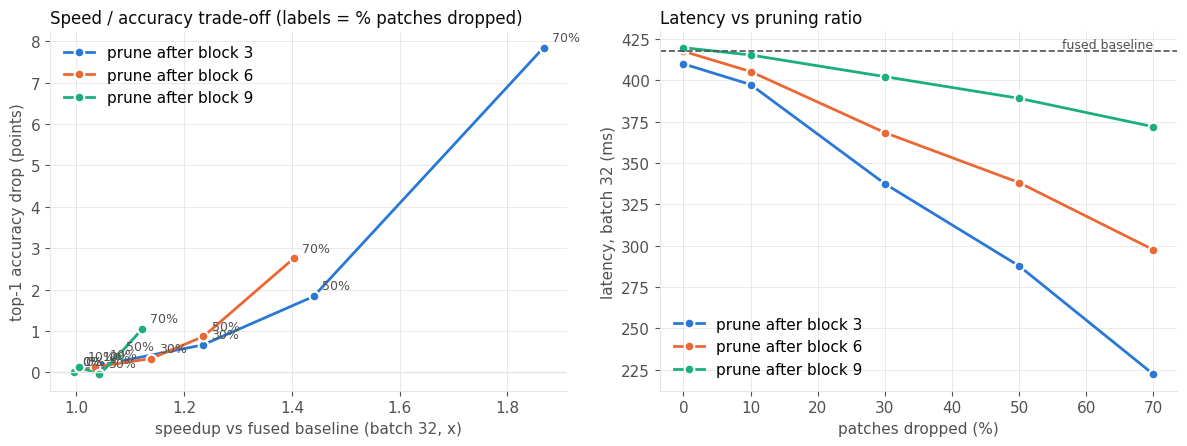

In [5]:
import matplotlib.pyplot as plt
COL = {LAYERS[i]: c for i, c in enumerate(["#2a78d6", "#eb6834", "#1baf7a"])}   # validated categorical slots 1-3
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

# (A) trade-off: speedup vs accuracy drop
ax = axes[0]
for L in LAYERS:
    d = res[res.layer == L].sort_values("K")
    ax.plot(d.speedup, d.acc_drop_pts, "-o", color=COL[L], lw=2, ms=7, mec="white", mew=1.5, label=f"prune after block {L}")
    for _, r in d.iterrows():
        ax.annotate(f"{r.K:.0%}", (r.speedup, r.acc_drop_pts), textcoords="offset points", xytext=(6, 5), fontsize=9, color=MUTED)
ax.axhline(0, color=GRID, lw=1); ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel("speedup vs fused baseline (batch 32, x)"); ax.set_ylabel("top-1 accuracy drop (points)")
ax.set_title("Speed / accuracy trade-off (labels = % patches dropped)", loc="left", color=INK, fontsize=12)
ax.legend(frameon=False)

# (B) latency vs K
ax = axes[1]
for L in LAYERS:
    d = res[res.layer == L].sort_values("K")
    ax.plot(d.K * 100, d.ms_b32, "-o", color=COL[L], lw=2, ms=7, mec="white", mew=1.5, label=f"prune after block {L}")
ax.axhline(b_ms, color=MUTED, lw=1.2, ls="--"); ax.text(KS[-1] * 100, b_ms, " fused baseline", va="bottom", ha="right", color=MUTED, fontsize=9)
ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel("patches dropped (%)"); ax.set_ylabel("latency, batch 32 (ms)")
ax.set_title("Latency vs pruning ratio", loc="left", color=INK, fontsize=12); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("day6_plots.png", dpi=160); plt.show()

**Recommended operating point: block 6, 30% dropped** → 89.1% top-1 (−0.33 points), 98.8% prediction
agreement, 1.14× at batch 32. Early pruning (block 3) has the highest ceiling (1.87× at 70%) but the
steepest accuracy cost; late pruning (block 9) is nearly free but caps at 1.12×. At batch 1 the speedup
is noisy and roughly flat: the T4 is launch-overhead bound there (~2.3 TFLOP/s effective).